# Combined corpora — reported capacity vs the vendor frontier

Both-corpora version of `capacity.ipynb` §5.1 / `arxiv/capacity.ipynb` §5.1: median
and 90th-percentile reported FP32 / VRAM, per device and per paper, for S2ORC
and arXiv on the same axes, against one shared vendor frontier line. Computed
through `accelscan.webexport.capacity_by_year`/`frontier`, so these numbers can
never drift from the single-corpus notebooks. Reported power (TDP) is analyzed
separately in the Appendix at the end of this notebook -- see that section for
why it is not in the main figure.

**Color scheme:** S2ORC in blues/greens (per device blue, per paper teal-green, as
in `capacity.ipynb`), arXiv in reds/oranges (per device vermillion, per paper
orange). The frontier line moves to a neutral dark purple/gray, since the original
frontier color (vermillion) is now one of arXiv's two series colors.

**Caveat** (inherited from `arxiv/capacity.ipynb`): arXiv's raw-LaTeX matching
biases any-mention prevalence upward relative to S2ORC, but reported capacity
(FP32/VRAM) is conditioned on the LLM confirming `used-in-this-work`, so this
figure is the one place cross-corpus *levels* are reasonably comparable, not just
trends -- both series are read off the same per-device/per-paper construction
against the same single vendor frontier.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import polars as pl
from accelscan import webexport as we
from accelscan.compute import spec_frame
from accelscan.paths import capacity_key, get_corpus, s3_uri
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import storage_options

# integer year ticks + every figure exported to output/analysis/combined/capacity_frontier/
setup_figures('combined/capacity_frontier')

## Knobs

In [2]:
COUNT_POLICY = 'floor1'
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
# Shared window for both corpora (not each corpus's own native window): arXiv's
# 2026 is a real partial year that would read as a slowdown in a per-year median,
# so both corpora and the frontier are restricted to the same complete years --
# matches the growth_stats.py tables' 2010-2025 window.
YEAR_MIN, YEAR_MAX = 2010, 2025
MIN_PAPERS_PER_YEAR = 25

# S2ORC: blues/greens (matches capacity.ipynb); arXiv: reds/oranges (Okabe-Ito).
# The frontier keeps neither: vermillion (the original C_FRONT) is now arXiv's
# per-device color, so it moves to a neutral dark purple for contrast against
# both pairs.
COLOR = {
    's2orc': {'per device': '#0072B2', 'per paper': '#009E73'},
    'arxiv': {'per device': '#D55E00', 'per paper': '#E69F00'},
}
CORPUS_LABEL = {'s2orc': 'S2ORC', 'arxiv': 'arXiv'}
C_FRONT = '#5B2C6F'

reg = load_registry(); so = storage_options()
specs = spec_frame(reg)

## Load per-paper capacity, both corpora

In [3]:
def load_cap(corpus_name):
    c = get_corpus(corpus_name)
    key = s3_uri(capacity_key(c, reg.version, PROMPT_VERSION, MODEL_TAG, COUNT_POLICY))
    cap = pl.read_parquet(key, storage_options=so)
    cap = cap.filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX))
    # A handful of rows have total_devices == 0 (a floored-count artifact, not a
    # real zero-device paper), which would otherwise divide 0/0 to NaN.
    return cap.with_columns(
        per_device_fp32_gflops=pl.when(pl.col('total_devices') > 0)
            .then(pl.col('reported_fp32_gflops') / pl.col('total_devices')),
        per_device_vram_gb=pl.when(pl.col('total_devices') > 0)
            .then(pl.col('reported_vram_gb') / pl.col('total_devices')),
        per_device_tdp_w=pl.when(pl.col('total_devices') > 0)
            .then(pl.col('reported_tdp_w') / pl.col('total_devices')))

cap_by_corpus = {name: load_cap(name) for name in COLOR}
for name, cap in cap_by_corpus.items():
    print(f'{CORPUS_LABEL[name]}: {cap.height:,} papers, {YEAR_MIN}-{YEAR_MAX}')

S2ORC: 231,991 papers, 2010-2025
arXiv: 170,544 papers, 2010-2025


## 5.1 Reported FLOPS and VRAM growth vs the vendor frontier -- both corpora

Same construction as the single-corpus §5.1: per-device is the like-for-like
series against the frontier (which is itself a single-device spec); per-paper
folds in scale-out and reads as "how many frontier GPUs' worth this paper
commanded." Solid marker = median, dashed = 90th-percentile; color identifies
corpus and quantity (see the knobs cell); one shared frontier line per panel.

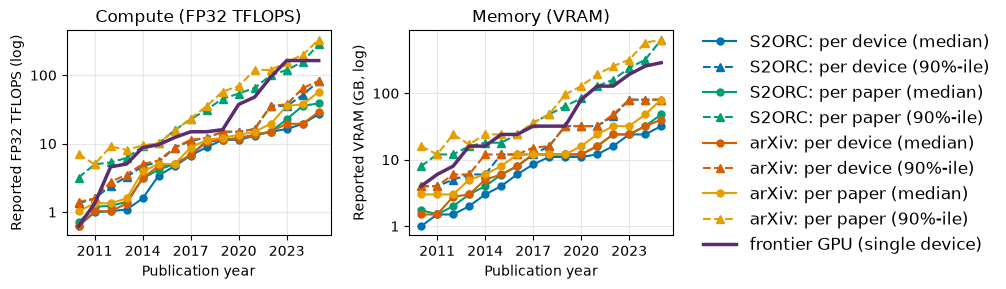

In [ ]:
PANELS = [  # per-device col, per-paper col, missing flag, spec col, scale, ylabel, title
    ('per_device_fp32_gflops', 'reported_fp32_gflops', 'spec_missing_fp32',
     'fp32_gflops', 1000, 'Reported FP32 TFLOPS (log)', 'Compute (FP32 TFLOPS)'),
    ('per_device_vram_gb', 'reported_vram_gb', 'spec_missing_vram',
     'vram_gb', 1, 'Reported VRAM (GB, log)', 'Memory (VRAM)'),
]

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (pdc, ppc, flag, spec, scale, ylab, ttl) in zip(axes, PANELS):
    for name, cap in cap_by_corpus.items():
        per_dev = we.capacity_by_year(cap, pdc, flag, MIN_PAPERS_PER_YEAR)
        per_paper = we.capacity_by_year(cap, ppc, flag, MIN_PAPERS_PER_YEAR)
        for d, color, qty in ((per_dev, COLOR[name]['per device'], 'per device'),
                              (per_paper, COLOR[name]['per paper'], 'per paper')):
            ax.plot(d['year'], d['med'] / scale, marker='o', ms=5, color=color,
                    label=f'{CORPUS_LABEL[name]}: {qty} (median)')
            ax.plot(d['year'], d['p90'] / scale, marker='^', ms=5.5, ls='--',
                    color=color, label=f'{CORPUS_LABEL[name]}: {qty} (90%-ile)')
    fr = we.frontier(specs, spec, YEAR_MIN, YEAR_MAX)
    ax.plot(fr['year'], fr['frontier'] / scale, color=C_FRONT, lw=2.5,
            label='frontier GPU (single device)', zorder=5)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set(xlabel='Publication year', ylabel=ylab, title=ttl)
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=11, ncol=1, loc='center left',
          bbox_to_anchor=(.99, 0.5), frameon=False)

plt.tight_layout(); plt.show()

## Appendix: Reported power (TDP), both corpora

TDP is too ambiguous to report with confidence alongside FP32/VRAM in the main
text -- see the Appendix in `capacity.ipynb`/`arxiv/capacity.ipynb` for the full
rationale (nameplate, not measured energy; the least spec-complete axis;
correlated with, not independent of, FP32/VRAM). Same construction as §5.1,
called on the TDP axis alone.

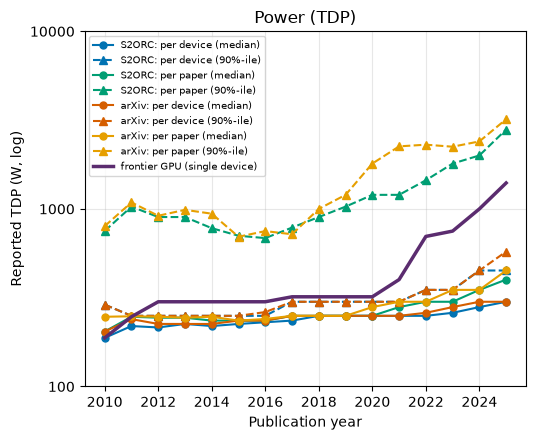

In [5]:
TDP_PANEL = ('per_device_tdp_w', 'reported_tdp_w', 'spec_missing_tdp',
            'tdp_w', 1, 'Reported TDP (W, log)', 'Power (TDP)')
pdc, ppc, flag, spec, scale, ylab, ttl = TDP_PANEL

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, cap in cap_by_corpus.items():
    per_dev = we.capacity_by_year(cap, pdc, flag, MIN_PAPERS_PER_YEAR)
    per_paper = we.capacity_by_year(cap, ppc, flag, MIN_PAPERS_PER_YEAR)
    for d, color, qty in ((per_dev, COLOR[name]['per device'], 'per device'),
                          (per_paper, COLOR[name]['per paper'], 'per paper')):
        ax.plot(d['year'], d['med'] / scale, marker='o', ms=5, color=color,
                label=f'{CORPUS_LABEL[name]}: {qty} (median)')
        ax.plot(d['year'], d['p90'] / scale, marker='^', ms=5.5, ls='--',
                color=color, label=f'{CORPUS_LABEL[name]}: {qty} (90%-ile)')
fr = we.frontier(specs, spec, YEAR_MIN, YEAR_MAX)
ax.plot(fr['year'], fr['frontier'] / scale, color=C_FRONT, lw=2.5,
        label='frontier GPU (single device)', zorder=5)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set(xlabel='Publication year', ylabel=ylab, title=ttl)
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=1, loc='upper left')

plt.tight_layout(); plt.show()